# House Area, Age and Property Price Prediction
## Notebook 1 — Dataset Exploration

**Course:** Probability and Statistics  
**Dataset:** Real Estate Valuation Data Set — UCI Machine Learning Repository (ID 477)  
**Citation:** Yeh, I. (2018). Real Estate Valuation [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5J30W  
**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

---
## Section 1 — Introduction

### What is this project about?
This project uses data from real property transactions to study how various factors are related to the **price per unit area** of residential properties.

We are studying questions like:
- Does an older house tend to sell for a lower price per unit area?
- Does being closer to a metro rail (MRT) station increase property prices?
- Do more nearby convenience stores raise the price?

### Where does the data come from?
The dataset is the **Real Estate Valuation Data Set** published by **I-Cheng Yeh** (2018) on the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set). It contains 414 historical property transactions collected from **Sindian District, New Taipei City, Taiwan**.

### What does each row represent?
Each row represents **one property transaction** — a single house that was bought or sold, recording characteristics at the time of the sale.

### Important limitation
> **Note on the project title:** The project title refers to "house area" and "property price," but this dataset does **not** contain total house area or total property price. The target variable is **price per unit area** (measured in units of 10,000 New Taiwan Dollars per Ping, where 1 Ping ≈ 3.3 m²). No total area or total price column exists in the data, and we will not invent one.

### Variables in the dataset
| Original column | Meaning | Unit |
|---|---|---|
| No | Observation identifier | ID |
| X1 transaction date | Date of property transaction | Decimal year |
| X2 house age | Age of property | Years |
| X3 distance to the nearest MRT station | Distance from nearest MRT station | Metres |
| X4 number of convenience stores | Nearby convenience stores | Count |
| X5 latitude | Geographic latitude | Degrees |
| X6 longitude | Geographic longitude | Degrees |
| Y house price of unit area | Property price per unit area | 10,000 NTD per Ping |

---
## Section 2 — Importing Libraries

We import only the necessary standard libraries for data manipulation, numerical analysis, and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visual style and random seed
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


---
## Section 3 — Loading the Dataset

We load the downloaded raw CSV file using pandas.

In [2]:
# Define data path relative to the notebooks folder
data_path = os.path.join('..', 'data', 'raw', 'real_estate_valuation.csv')

# Load the dataset
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded.")
print(f"Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset successfully loaded.
Dimensions: 414 rows, 8 columns


---
## Section 4 — Initial Inspection

We inspect the first five rows, last five rows, dimensions, column names, data types, and structural info.

In [3]:
# First 5 rows
print("First 5 rows:")
df.head()

First 5 rows:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [4]:
# Last 5 rows
print("Last 5 rows:")
df.tail()

Last 5 rows:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5
413,414,2013.500,6.5,90.45606,9,24.97433,121.54310,63.9


In [5]:
# Dimensions
print(f"Number of rows    : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")

Number of rows    : 414
Number of columns : 8


In [6]:
# Column names
print("Column names:")
for idx, col in enumerate(df.columns, start=1):
    print(f"  {idx}. {col}")

Column names:
  1. No
  2. X1 transaction date
  3. X2 house age
  4. X3 distance to the nearest MRT station
  5. X4 number of convenience stores
  6. X5 latitude
  7. X6 longitude
  8. Y house price of unit area


In [7]:
# Data types
print("Data types:")
print(df.dtypes)

Data types:
No                                          int64
X1 transaction date                       float64
X2 house age                              float64
X3 distance to the nearest MRT station    float64
X4 number of convenience stores             int64
X5 latitude                               float64
X6 longitude                              float64
Y house price of unit area                float64
dtype: object


In [8]:
# Concise dataset information
print("Dataset Info:")
df.info()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


---
## Section 5 — Dataset Quality Check

We systematically verify data quality: missing values, duplicate records, unique values, presence of identifier column, and numerical data types.

In [9]:
# 5.1 Missing values per column
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts)
print(f"Total missing values: {missing_counts.sum()}")

Missing values per column:
No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64
Total missing values: 0


In [10]:
# 5.2 Duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [11]:
# 5.3 Unique values per column
print("Unique values per column:")
print(df.nunique())

Unique values per column:
No                                        414
X1 transaction date                        12
X2 house age                              236
X3 distance to the nearest MRT station    259
X4 number of convenience stores            11
X5 latitude                               234
X6 longitude                              232
Y house price of unit area                270
dtype: int64


In [12]:
# 5.4 Check identifier column 'No'
if 'No' in df.columns:
    print(f"'No' column exists. Range: {df['No'].min()} to {df['No'].max()} (Total: {df['No'].nunique()} unique IDs).")
    print("Note: 'No' is an observation identifier and will NOT be used as a predictive feature.")
else:
    print("'No' column is not present.")

'No' column exists. Range: 1 to 414 (Total: 414 unique IDs).
Note: 'No' is an observation identifier and will NOT be used as a predictive feature.


In [13]:
# 5.5 Check numerical vs non-numerical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
non_num_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Non-numerical columns ({len(non_num_cols)}): {non_num_cols}")

Numerical columns (8): ['No', 'X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']
Non-numerical columns (0): []


---
## Section 6 — Descriptive Overview

We compute summary statistics: mean, median, standard deviation, minimum, maximum, and quartiles. We exclude the identifier column `No` from descriptive statistics.

In [14]:
# Exclude 'No' for statistical analysis
df_stats = df.drop(columns=['No']) if 'No' in df.columns else df

print("Descriptive Statistics (excluding 'No'):")
df_stats.describe().round(3)

Descriptive Statistics (excluding 'No'):


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000,414.000,414.000,414.000,414.000,414.000,414.000
mean,2013.149,17.713,1083.886,4.094,24.969,121.533,37.980
std,0.282,11.392,1262.110,2.946,0.012,0.015,13.606
min,2012.667,0.000,23.383,0.000,24.932,121.474,7.600
25%,2012.917,9.025,289.325,1.000,24.963,121.528,27.700
50%,2013.167,16.100,492.231,4.000,24.971,121.539,38.450
75%,2013.417,28.150,1454.279,6.000,24.977,121.543,46.600
max,2013.583,43.800,6488.021,10.000,25.015,121.566,117.500


In [15]:
# Calculate Medians explicitly
print("Median values:")
print(df_stats.median().round(3))

Median values:
X1 transaction date                       2013.167
X2 house age                                16.100
X3 distance to the nearest MRT station     492.231
X4 number of convenience stores              4.000
X5 latitude                                 24.971
X6 longitude                               121.539
Y house price of unit area                  38.450
dtype: float64


In [16]:
# Summary for Target Variable (Y house price of unit area)
target_col = 'Y house price of unit area'
print(f"Target Variable: {target_col}")
print(f"  Mean               : {df[target_col].mean():.3f} (10,000 NTD/Ping)")
print(f"  Median             : {df[target_col].median():.3f} (10,000 NTD/Ping)")
print(f"  Standard Deviation : {df[target_col].std():.3f}")
print(f"  Minimum            : {df[target_col].min():.3f}")
print(f"  Maximum            : {df[target_col].max():.3f}")

Target Variable: Y house price of unit area
  Mean               : 37.980 (10,000 NTD/Ping)
  Median             : 38.450 (10,000 NTD/Ping)
  Standard Deviation : 13.606
  Minimum            : 7.600
  Maximum            : 117.500


---
## Section 7 — Initial Visualizations

We generate five clear, properly labelled plots and save them to `outputs/figures/`:
1. Histogram of house age (`X2`)
2. Histogram of house price per unit area (`Y`)
3. Histogram of distance to nearest MRT station (`X3`)
4. Boxplot of house price per unit area (`Y`)
5. Scatter plot of house age versus house price per unit area (`X2` vs `Y`)

In [17]:
# Ensure output directory exists
figures_dir = os.path.join('..', 'outputs', 'figures')
os.makedirs(figures_dir, exist_ok=True)
print(f"Saving figures to: {figures_dir}")

Saving figures to: ..\outputs\figures


### 7.1 Histogram of House Age (X2)

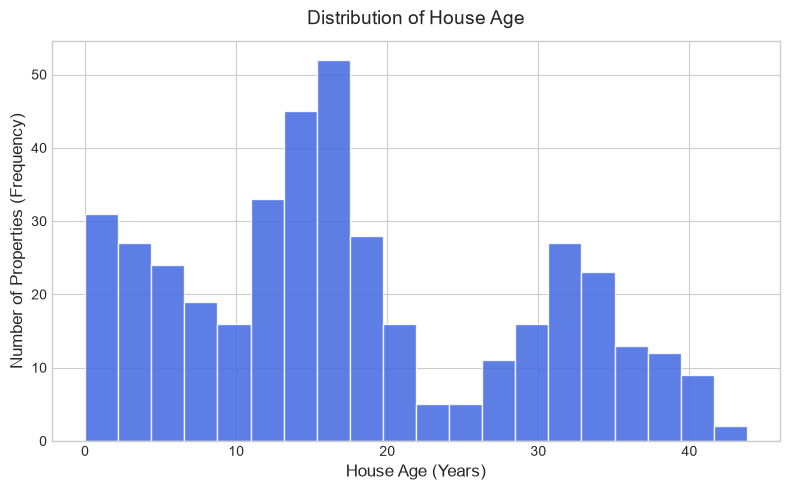

Saved: ..\outputs\figures\01_histogram_house_age.png


In [18]:
plt.figure(figsize=(8, 5))
plt.hist(df['X2 house age'], bins=20, color='royalblue', edgecolor='white', alpha=0.85)
plt.title('Distribution of House Age', fontsize=14, pad=12)
plt.xlabel('House Age (Years)', fontsize=12)
plt.ylabel('Number of Properties (Frequency)', fontsize=12)
plt.tight_layout()
fig1_path = os.path.join(figures_dir, '01_histogram_house_age.png')
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

### 7.2 Histogram of House Price per Unit Area (Y)

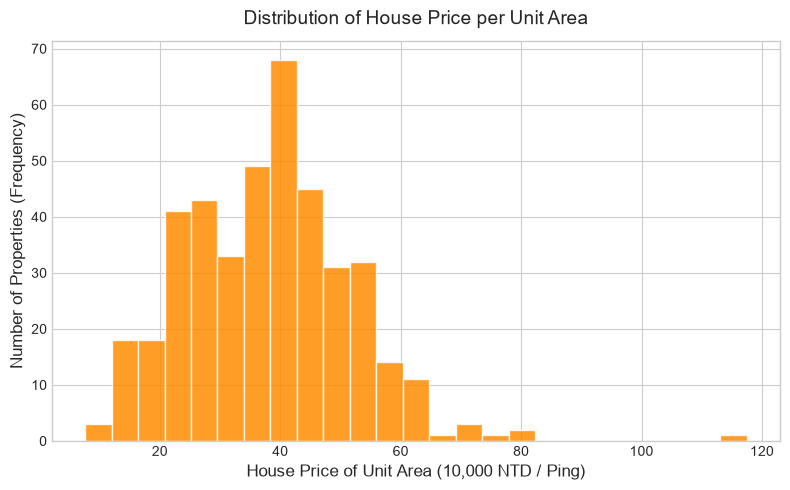

Saved: ..\outputs\figures\02_histogram_house_price.png


In [19]:
plt.figure(figsize=(8, 5))
plt.hist(df['Y house price of unit area'], bins=25, color='darkorange', edgecolor='white', alpha=0.85)
plt.title('Distribution of House Price per Unit Area', fontsize=14, pad=12)
plt.xlabel('House Price of Unit Area (10,000 NTD / Ping)', fontsize=12)
plt.ylabel('Number of Properties (Frequency)', fontsize=12)
plt.tight_layout()
fig2_path = os.path.join(figures_dir, '02_histogram_house_price.png')
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")

### 7.3 Histogram of Distance to Nearest MRT Station (X3)

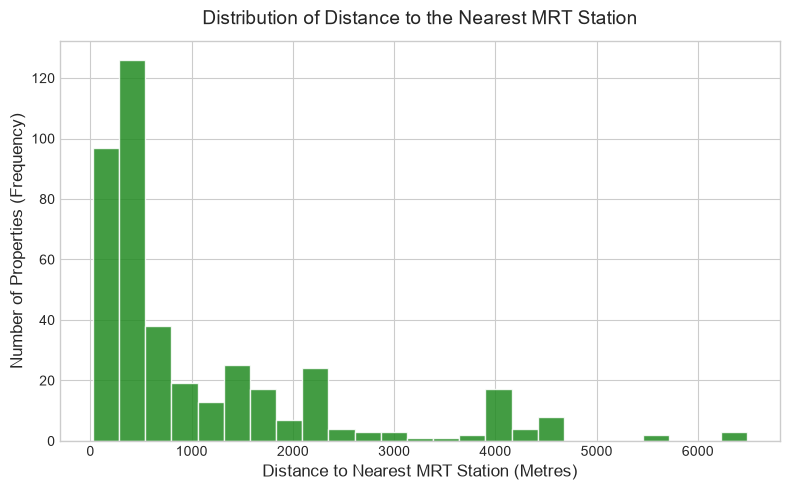

Saved: ..\outputs\figures\03_histogram_mrt_distance.png


In [20]:
plt.figure(figsize=(8, 5))
plt.hist(df['X3 distance to the nearest MRT station'], bins=25, color='forestgreen', edgecolor='white', alpha=0.85)
plt.title('Distribution of Distance to the Nearest MRT Station', fontsize=14, pad=12)
plt.xlabel('Distance to Nearest MRT Station (Metres)', fontsize=12)
plt.ylabel('Number of Properties (Frequency)', fontsize=12)
plt.tight_layout()
fig3_path = os.path.join(figures_dir, '03_histogram_mrt_distance.png')
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"Saved: {fig3_path}")

### 7.4 Boxplot of House Price per Unit Area (Y)

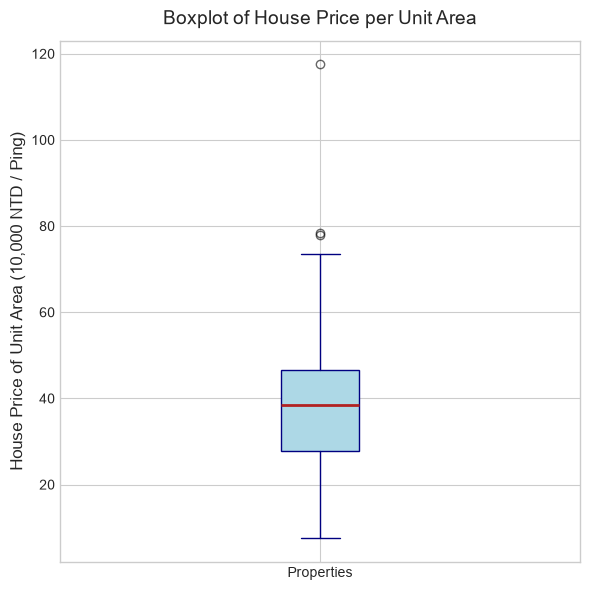

Saved: ..\outputs\figures\04_boxplot_house_price.png


In [21]:
plt.figure(figsize=(6, 6))
plt.boxplot(df['Y house price of unit area'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='firebrick', linewidth=2),
            whiskerprops=dict(color='navy'),
            capprops=dict(color='navy'),
            flierprops=dict(marker='o', color='firebrick', alpha=0.6))
plt.title('Boxplot of House Price per Unit Area', fontsize=14, pad=12)
plt.ylabel('House Price of Unit Area (10,000 NTD / Ping)', fontsize=12)
plt.xticks([1], ['Properties'])
plt.tight_layout()
fig4_path = os.path.join(figures_dir, '04_boxplot_house_price.png')
plt.savefig(fig4_path, dpi=300)
plt.show()
print(f"Saved: {fig4_path}")

### 7.5 Scatter Plot: House Age vs House Price per Unit Area

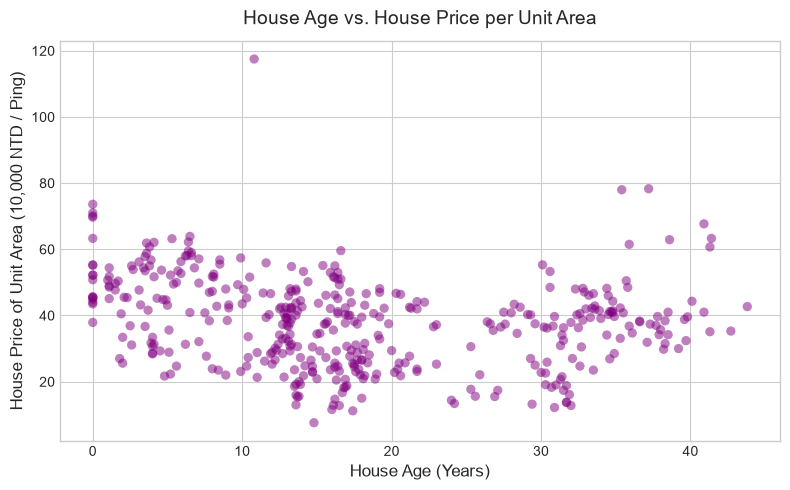

Saved: ..\outputs\figures\05_scatter_age_vs_price.png


In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(df['X2 house age'], df['Y house price of unit area'],
            color='purple', alpha=0.5, edgecolors='none', s=45)
plt.title('House Age vs. House Price per Unit Area', fontsize=14, pad=12)
plt.xlabel('House Age (Years)', fontsize=12)
plt.ylabel('House Price of Unit Area (10,000 NTD / Ping)', fontsize=12)
plt.tight_layout()
fig5_path = os.path.join(figures_dir, '05_scatter_age_vs_price.png')
plt.savefig(fig5_path, dpi=300)
plt.show()
print(f"Saved: {fig5_path}")

---
## Section 8 — Dataset Interpretation

Based strictly on the verified outputs from our exploration:

1. **House Age (`X2`)**:
   - Ranges from 0.0 to 43.8 years, with a mean of ~17.71 years and median of 16.10 years.
   - The histogram shows a bimodal structure with noticeable concentrations of both newer properties (<10 years) and mature properties (~30–40 years).

2. **House Price per Unit Area (`Y`)**:
   - Ranges from 7.6 to 117.5 (10,000 NTD/Ping), with a mean of 37.98 and median of 38.45.
   - The majority of properties lie between ~25 and ~50 units. The boxplot and histogram highlight a prominent extreme outlier at 117.5.

3. **Distance to Nearest MRT Station (`X3`)**:
   - Ranges from 23.38 to 6488.02 metres, with a mean of 1083.89 m and median of 492.23 m.
   - Distribution is strongly right-skewed; over half the properties are within 500 metres of an MRT station, but a long tail extends beyond 3,000 metres.

4. **Convenience Stores (`X4`)**:
   - Properties have between 0 and 10 nearby convenience stores, with an average of 4.09.

5. **House Age vs Price Relationship**:
   - The scatter plot does not show a simple strictly monotonic linear trend; both very new properties and select older properties exhibit diverse pricing. Formal correlation and statistical testing in upcoming stages will quantify this relationship.

---
## Section 9 — Sampling and Dataset Limitations

1. **Sample Size**:
   - The dataset contains 414 historical observations.

2. **Geographical Scope**:
   - Data collection was conducted in Sindian District, New Taipei City, Taiwan.
   - Findings cannot be directly generalized to other cities, rural regions, or international housing markets where infrastructure, density, and market mechanisms differ.

3. **Sampling Procedure**:
   - The official UCI documentation does not provide details on whether transactions were randomly sampled, consecutive sales, or selected by specific agency criteria. Therefore, representativeness of the overall Taiwan market cannot be assumed.

4. **Temporal Context**:
   - Transactions occurred between 2012 and 2013 (decimal year 2012.667 to 2013.583). Market conditions, interest rates, and inflation have changed since this window.

5. **Target Variable & Missing Total Area**:
   - The target variable is **price per unit area** (10,000 NTD / Ping, where 1 Ping ≈ 3.3 m²).
   - The dataset **does not record total house floor area or total transaction price**. We do not invent either variable, and predictions apply strictly to unit-area valuation.

In [23]:
# Verification of generated figures in outputs/figures/
print("Generated figure files:")
for f in sorted(os.listdir(figures_dir)):
    print(f"  - {f}")

Generated figure files:
  - 01_histogram_house_age.png
  - 02_histogram_house_price.png
  - 03_histogram_mrt_distance.png
  - 04_boxplot_house_price.png
  - 05_scatter_age_vs_price.png
